# Time series analysis

        This notebook uses the development outputs from `python scripts/run_eda.py`.
        Run that command from the project root before starting a fresh kernel.

In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))
from src import config

## Station coverage and gaps

Each station's coverage is measured over the calendar days from its first to its last
development observation. Long gaps limit the usable history for lag and rolling features.
The table summarizes coverage across stations and lists the stations with the lowest
coverage.

In [2]:
temporal = pd.read_csv(config.RESULTS / "Exploratory_temporal.csv")
gaps = pd.read_csv(config.PARTS / "gap_report_enhanced.csv").set_index("station_id")
columns = [
    "number_of_rows", "missing_calendar_days", "calendar_coverage_percentage",
    "longest_missing_streak_days", "longest_continuous_run_days",
]
display(gaps[columns].agg(["min", "median", "max"]).round(2))
display(gaps.nsmallest(8, "calendar_coverage_percentage")[columns].round(2))

,number_of_rows,missing_calendar_days,calendar_coverage_percentage,longest_missing_streak_days,longest_continuous_run_days
min,2.0,0.0,4.53,0.0,1.0
median,416.5,609.5,47.74,116.0,17.5
max,814.0,2632.0,100.00,2382.0,32.0


,number_of_rows,missing_calendar_days,calendar_coverage_percentage,longest_missing_streak_days,longest_continuous_run_days
station_id,,,,,
"C. Restoy, 51, Almeria, Spain",21,443,4.53,432,10
VALÈNCIA - MOLÍ DEL SOL,319,2632,10.81,2382,30
VILAMARXANT,310,2118,12.77,343,11
ONTINYENT,398,2379,14.33,167,16
FR03029,253,768,24.78,126,16
FR03006,260,768,25.29,126,18
FR03043,269,760,26.14,126,17
FR03030,283,643,30.56,75,16


## Seasonal and weekly patterns

The monthly and yearly plots pool available station-days. The station mix and number of
observations vary across periods, so the pooled differences are descriptive.
Weekday medians and within-segment lag-seven correlations give complementary views of the
weekly pattern. The median lag-seven association is weak and does not establish a weekly cycle.

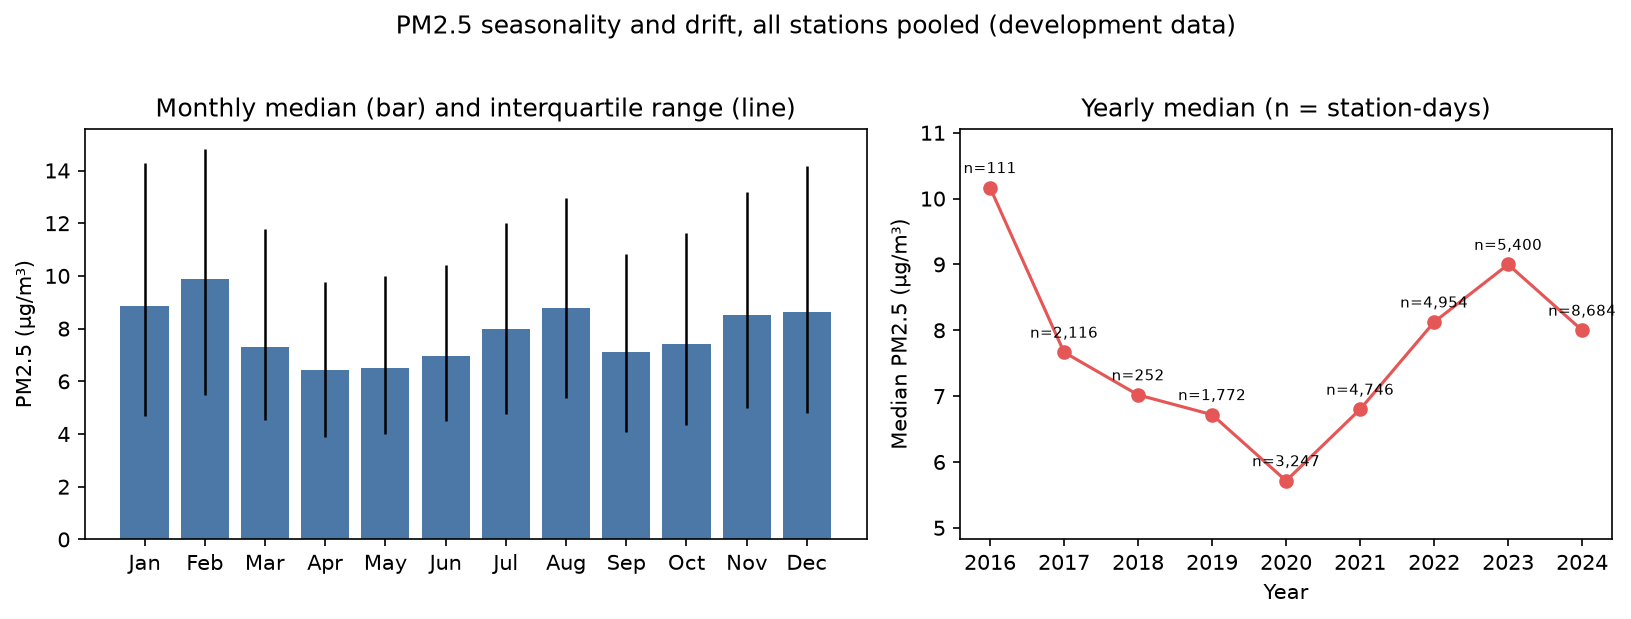

,weekday,n_obs,n_stations,median,iqr
189,Mon,4689,69,7.789,7.444
198,Tue,4609,69,7.750,7.347
207,Wed,4380,68,8.000,7.619
216,Thu,4236,68,7.788,7.792
225,Fri,4596,69,7.667,7.600
234,Sat,4709,69,7.600,7.229
243,Sun,4063,69,7.500,7.020


,metric,value,note
59870,median_pearson_lag_7,-0.08975607073732969,123 segments; association alone cannot establi...


In [3]:
display(Image(filename=str(config.FIGURES / "m4_seasonal_profile.png"), width=900))
profiles = pd.read_csv(config.PARTS / "thursday_temporal_profiles.csv")
weekday = profiles.loc[
    profiles["period"].eq("weekday") & profiles["variable"].eq("pm25"),
    ["value", "n_obs", "n_stations", "median", "iqr"],
].copy()
names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
weekday["value"] = weekday["value"].astype(int).map(dict(enumerate(names)))
display(weekday.rename(columns={"value": "weekday"}).round(3))
display(temporal.loc[temporal["metric"].eq("median_pearson_lag_7"), ["metric", "value", "note"]])

## ACF, PACF, and formal tests

The ACF and PACF use uninterrupted PM2.5 runs with at least 30 daily observations.
Only six segments qualify. The ADF test checks for a unit root, while Ljung–Box checks
autocorrelation at the listed lags. The short series and narrow coverage make
stationarity inconclusive across stations. Ljung–Box here concerns the PM2.5 series.

Matplotlib is building the font cache; this may take a moment.


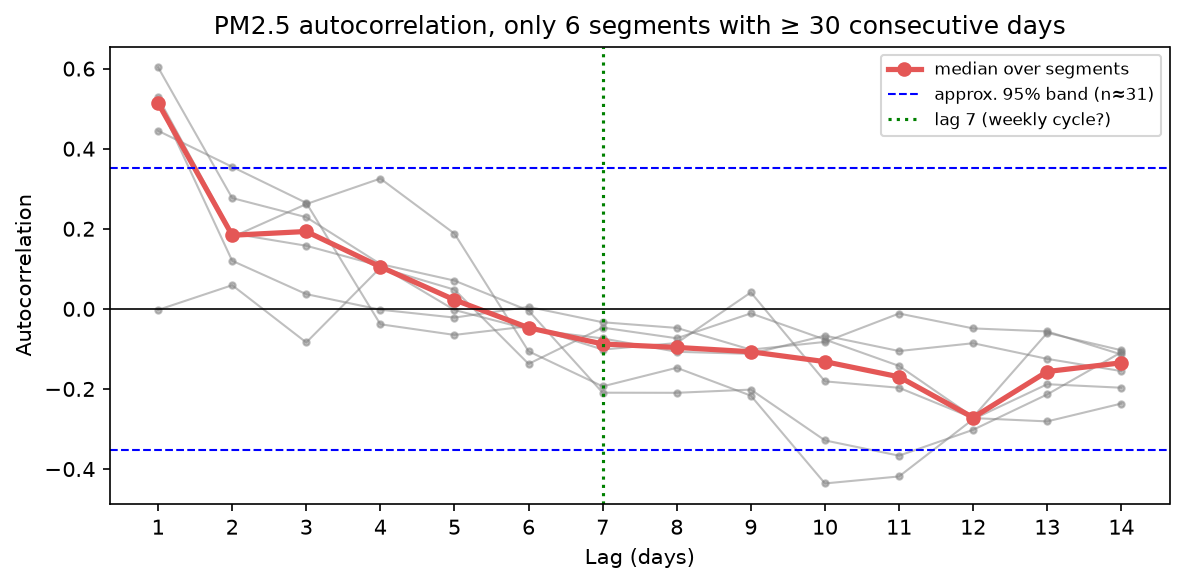

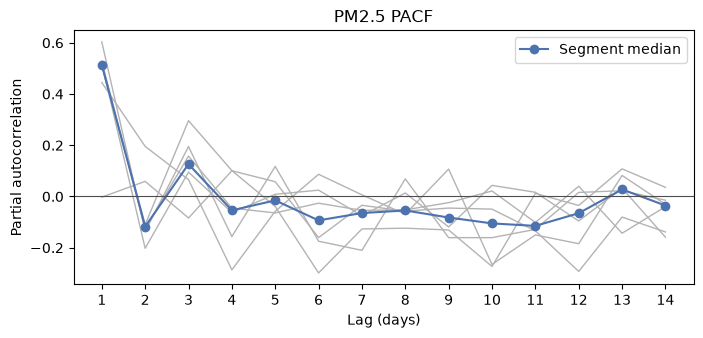

,metric,adf_statistic,adf_pvalue,ljung_box_pvalue_lag_7,ljung_box_pvalue_lag_14
group,note,,,,
LA ALJORRA,segment=34; observations=32,-2.5813,0.0969,0.0053,0.0000
MEDITERRÁNEO,segment=209; observations=32,-5.2926,0.0000,0.9710,0.8791
MOLINA DE SEGURA,segment=34; observations=31,-3.1996,0.0200,0.0433,0.0069
VALÈNCIA - MOLÍ DEL SOL,segment=62; observations=30,-2.3330,0.1615,0.2198,0.6484
VALÈNCIA OLIVERETA,segment=32; observations=30,-2.1342,0.2310,0.0978,0.2747
VALÈNCIA-CENTRE,segment=32; observations=31,-1.8441,0.3588,0.0056,0.0000


In [4]:
import matplotlib.pyplot as plt

display(Image(filename=str(config.FIGURES / "m4_acf_pm25.png"), width=750))
diagnostics = temporal.loc[temporal["section"].eq("temporal_dependence")].copy()
pacf = diagnostics.loc[diagnostics["metric"].str.startswith("pacf_lag_")].copy()
pacf["lag"] = pacf["metric"].str.removeprefix("pacf_lag_").astype(int)
pacf["value"] = pd.to_numeric(pacf["value"])
wide = pacf.pivot(index="lag", columns=["group", "note"], values="value")
fig, ax = plt.subplots(figsize=(8, 3.3))
ax.plot(wide.index, wide, color="0.7", linewidth=1)
ax.plot(wide.index, wide.median(axis=1), "-o", color="#4C72B0", label="Segment median")
ax.axhline(0, color="0.3", linewidth=0.8)
ax.set(xlabel="Lag (days)", ylabel="Partial autocorrelation", title="PM2.5 PACF", xticks=wide.index)
ax.legend()
plt.show()

tests = ["adf_statistic", "adf_pvalue", "ljung_box_pvalue_lag_7", "ljung_box_pvalue_lag_14"]
formal = diagnostics.loc[diagnostics["metric"].isin(tests)].copy()
formal["value"] = pd.to_numeric(formal["value"])
display(formal.pivot(index=["group", "note"], columns="metric", values="value")[tests].round(4))

## Lead–lag results

Positive lags refer to past predictor observations. AOD shows stronger same-day
association than one-day lead association in this segment screen. Temperature and O₃
show larger one-day associations in absolute magnitude. The measurements are usable for
forecasting only if available by issuance time. The plot and table summarize median
correlations across eligible segments.

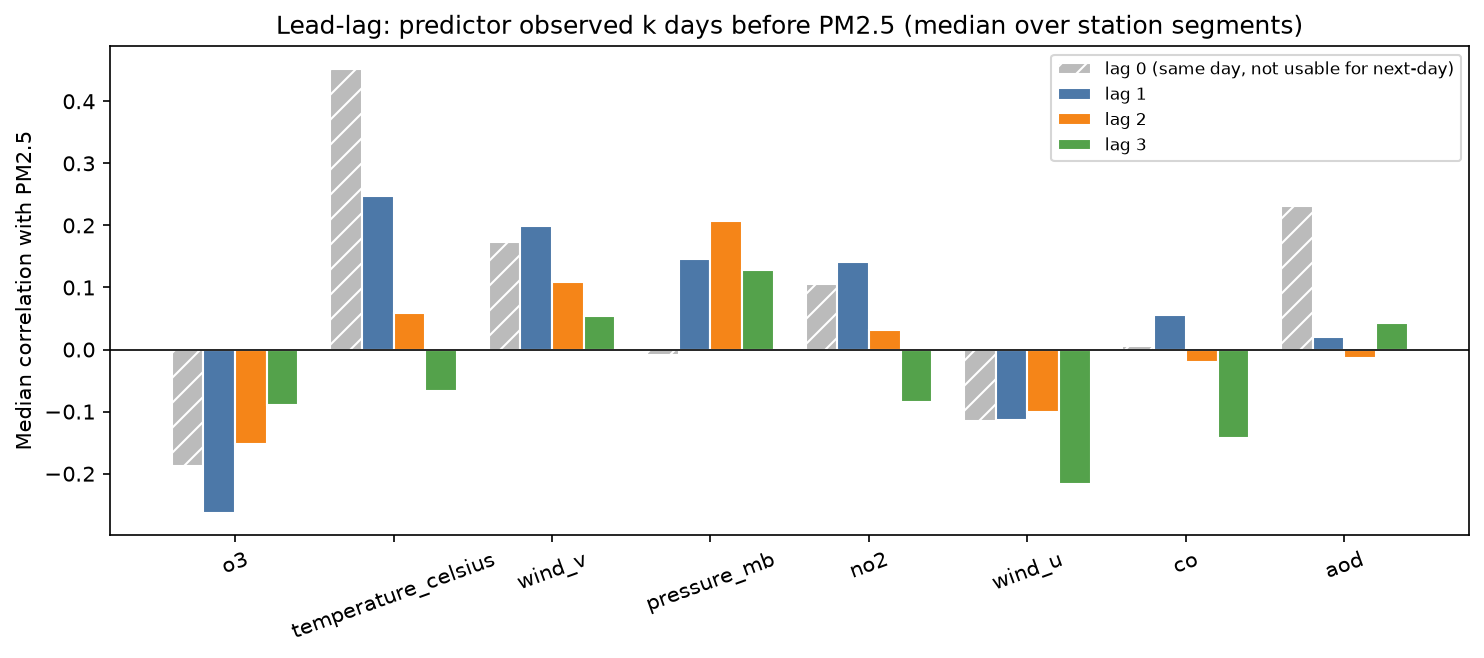

group,lag_0d,lag_1d,lag_2d,lag_3d
variable,,,,
aod,0.231,0.020,-0.014,0.042
co,0.005,0.056,-0.020,-0.142
no2,0.105,0.142,0.031,-0.085
o3,-0.188,-0.263,-0.152,-0.090
pressure_mb,-0.009,0.146,0.208,0.128
temperature_celsius,0.453,0.247,0.059,-0.067
wind_u,-0.116,-0.114,-0.101,-0.217
wind_v,0.173,0.199,0.109,0.054


In [5]:
display(Image(filename=str(config.FIGURES / "m4_lead_lag.png"), width=825))
lags = ["lag_0d", "lag_1d", "lag_2d", "lag_3d"]
lead = temporal.loc[
    temporal["section"].eq("lead_lag_segments") & temporal["group"].isin(lags)
].copy()
lead["value"] = pd.to_numeric(lead["value"])
display(lead.pivot(index="variable", columns="group", values="value")[lags].round(3))

## Lag features and temporal validation

Test the exact previous-day PM2.5 value for rolling next-day forecasts only when that
value would already have been released. Reset histories at date gaps or metadata changes.
Keep a missing-lag indicator and compare the same validation rows with a calendar-only
baseline. Actual release times remain unverified. Exclude target-history features from
same-day and cold-start experiments. Longer windows remain exploratory.

The shared temporal splits use expanding training windows and a full calendar day between
training and validation. Their date boundaries and row counts below come from the saved
fold file. Station observations on the same date stay together.

In [6]:
import json

persistence = temporal.loc[
    temporal["section"].eq("temporal_gate")
    & temporal["variable"].eq("pm25") & temporal["group"].eq("lag_1d"),
    ["metric", "value"],
]
display(persistence.set_index("metric").rename(columns={"value": "PM2.5 lag 1 day"}))

payload = json.loads((config.FOLDS / "folds_temporal.json").read_text())
display(pd.DataFrame([
    {
        "fold": number,
        "train rows": len(fold["train"]),
        "validation rows": len(fold["val"]),
        "validation starts": fold["validation_calendar_start"],
        "validation ends": fold["validation_calendar_end"],
    }
    for number, fold in enumerate(payload["folds"], start=1)
]).set_index("fold"))

,PM2.5 lag 1 day
metric,
n_pairs,20496.0
median_station_spearman,0.6947022178282882
stations_estimable,68.0
stations_positive,68.0


,train rows,validation rows,validation starts,validation ends
fold,,,,
1,2339,1788,2018-04-03,2019-08-08
2,4118,3201,2019-08-09,2020-12-13
3,7328,6904,2020-12-14,2022-04-20
4,14232,5881,2022-04-21,2023-08-26
5,20113,11169,2023-08-27,2024-12-31
